# El benchmark de diez por diez de los hologramas analíticos

**Pregunta:** ¿Reproducen las líneas base analíticas, la superposición, la superposición aleatoria y la máscara aleatoria, la comparación publicada de 10 por 10 cuando corren en la grilla propia de DinHot, y qué de la grilla decide la respuesta?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebook 01 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Una línea base solo sirve si se sabe que es correcta. El artículo que introdujo el algoritmo ponderado imprimió una tabla de tres hologramas analíticos sobre un arreglo de 10 por 10, y esa tabla es la vara de medir de todos los métodos posteriores. DinHot no usa el SLM de 768 por 768 píxeles del artículo, usa 256 por 256, de modo que una diferencia con la tabla podría ser un error o una consecuencia de la grilla. Moverás el mismo arreglo a cinco tamaños de SLM, ejecutarás los tres métodos en cada uno, leerás los píxeles por trampa como la variable que importa, compararás el resultado de 768 por 768 con los números publicados y probarás otras dos explicaciones de las diferencias: el haz y la cuantización de 8 bits del dispositivo del artículo.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, luego los módulos del pipeline por su ruta
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.device import quantize
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import snap_to_bins
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m01_superposition, m02_random_superposition, m03_random_mask

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def array_numbers(phi, setup, traps):
    """Eficiencia, uniformidad y dispersión relativa (por ciento) de un holograma leído con la forma puntual."""
    i = metrics.trap_intensities(forward.point_trap_fields(phi, setup, traps))
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot, para el arreglo; los valores publicados son los impresos en Di Leonardo et al. 2007, Tabla 1, https://doi.org/10.1364/OE.15.001913.
- Clase de licencia: caso sintético escrito por el producto; los números publicados se citan como hechos con su fuente.
- Archivo leído: `data/examples/cases.json`, caso C12, y tres semillas contadas desde su semilla.

In [2]:
# el caso C12 da el arreglo; los valores publicados por Di Leonardo et al. 2007 son la columna de referencia
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C12_calibration"]
base_setup = setup_of(rec)
base_traps = target_of(rec).traps
published = {"M01": (0.29, 0.01, 257.0), "M02": (0.69, 0.01, 89.0), "M03": (0.01, 0.58, 16.0)}
budget = Budget(1)
seeds = [rec["seed"] + k for k in range(3)]
print(f"{len(base_traps)} trampas, SLM {base_setup.n_pix} x {base_setup.n_pix}, {len(seeds)} semillas")

100 trampas, SLM 256 x 256, 3 semillas


## Método

Los tres métodos son los del notebook anterior, y las métricas son la eficiencia $e$, la uniformidad $u$ y la dispersión relativa $\sigma$ del tema 01. La fila publicada es, para la superposición, $e = 0,29$, $u = 0,01$, $\sigma = 257$ por ciento; para la superposición aleatoria, $0,69$, $0,01$ y $89$ por ciento; para la máscara aleatoria, $0,01$, $0,58$ y $16$ por ciento, todo con 768 por 768 píxeles y 8 bits (Di Leonardo et al. 2007, Tabla 1). La grilla entra en la física en un solo lugar que aquí importa: la máscara aleatoria da a cada trampa $N/M$ píxeles y el resto de los píxeles son ruido sobre ella, de modo que su uniformidad debería mejorar con $N/M$ y su dispersión debería seguir $\sqrt{2}\,M/\sqrt{N}$ (notebook 01). Los otros dos métodos no tienen esa dependencia. El plan es mantener fijos el arreglo y el tamaño físico del SLM y cambiar solo el número de píxeles, que es exactamente lo que hace `replace(setup, n_pix=n)`, y luego mover cada trampa al bin más cercano de la nueva grilla focal con `snap_to_bins`, porque el tamaño del bin cambia con $N$.

La primera celda construye cinco configuraciones, de 128 por 128 a 768 por 768 píxeles, y mueve el arreglo a cada grilla focal. Imprime los píxeles por trampa, que es la variable que usa el argumento, y la mayor distancia que tuvo que moverse una trampa: si es cero el arreglo es el mismo en todas las grillas.

In [3]:
# el mismo arreglo en cinco tamaños de SLM: las posiciones de las trampas se llevan al bin más cercano de cada grilla
sizes = [128, 256, 384, 512, 768]
grids = {}
for n in sizes:
    setup_n = replace(base_setup, n_pix=n)
    traps_n = snap_to_bins(setup_n, base_traps)
    shift_um = np.hypot(traps_n.x_m - base_traps.x_m, traps_n.y_m - base_traps.y_m).max() * 1e6
    grids[n] = (setup_n, Target.from_traps(traps_n))
    print(f"{n} x {n}: {n * n / len(traps_n):5.0f} píxeles por trampa")
    print(f"        mayor desplazamiento de una trampa a la grilla: {shift_um:.3f} um")

128 x 128:   164 píxeles por trampa
        mayor desplazamiento de una trampa a la grilla: 0.000 um
256 x 256:   655 píxeles por trampa
        mayor desplazamiento de una trampa a la grilla: 0.000 um
384 x 384:  1475 píxeles por trampa
        mayor desplazamiento de una trampa a la grilla: 0.000 um
512 x 512:  2621 píxeles por trampa
        mayor desplazamiento de una trampa a la grilla: 0.000 um
768 x 768:  5898 píxeles por trampa
        mayor desplazamiento de una trampa a la grilla: 0.000 um


La superposición es determinista, así que basta una corrida por grilla.

In [4]:
# M01 en cada grilla: un holograma determinista por tamaño
table = {"M01": {}, "M02": {}, "M03": {}}
for n, (setup_n, target_n) in grids.items():
    res = m01_superposition.run(setup_n, target_n, budget=budget, rng=Rng(seeds[0]))
    table["M01"][n] = np.array([array_numbers(res.phi, setup_n, target_n.traps)])
    e, u, sigma = table["M01"][n][0]
    print(f"M01 {n:3d}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

M01 128: e = 0.3248, u = 0.0002, sigma = 271.89 %
M01 256: e = 0.3280, u = 0.0003, sigma = 268.79 %
M01 384: e = 0.3286, u = 0.0003, sigma = 268.22 %
M01 512: e = 0.3288, u = 0.0003, sigma = 268.02 %
M01 768: e = 0.3290, u = 0.0003, sigma = 267.88 %


La superposición aleatoria corre con tres semillas en cada grilla, y la celda imprime el promedio de los tres números.

In [5]:
# M02 en cada grilla, el promedio sobre las semillas
for n, (setup_n, target_n) in grids.items():
    runs = [m02_random_superposition.run(setup_n, target_n, budget=budget, rng=Rng(s)) for s in seeds]
    table["M02"][n] = np.array([array_numbers(r.phi, setup_n, target_n.traps) for r in runs])
    e, u, sigma = table["M02"][n].mean(axis=0)
    print(f"M02 {n:3d}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

M02 128: e = 0.7361, u = 0.1803, sigma = 40.78 %
M02 256: e = 0.7361, u = 0.1829, sigma = 40.66 %
M02 384: e = 0.7361, u = 0.1834, sigma = 40.64 %
M02 512: e = 0.7361, u = 0.1836, sigma = 40.63 %
M02 768: e = 0.7361, u = 0.1837, sigma = 40.63 %


La máscara aleatoria es la cara, porque cada trampa construye su propia fase sobre todo el SLM; la celda ejecuta tres semillas en cada grilla y guarda el primer holograma de la grilla mayor para la prueba de cuantización de más abajo.

In [6]:
# M03 en cada grilla, el promedio sobre las semillas (la grilla de 768 x 768 es la que más tarda)
phases_768 = {}
for n, (setup_n, target_n) in grids.items():
    runs = [m03_random_mask.run(setup_n, target_n, budget=budget, rng=Rng(s)) for s in seeds]
    table["M03"][n] = np.array([array_numbers(r.phi, setup_n, target_n.traps) for r in runs])
    phases_768[n] = runs[0].phi
    e, u, sigma = table["M03"][n].mean(axis=0)
    print(f"M03 {n:3d}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

M03 128: e = 0.0153, u = 0.0017, sigma = 78.05 %
M03 256: e = 0.0101, u = 0.0628, sigma = 50.97 %
M03 384: e = 0.0094, u = 0.2649, sigma = 35.12 %
M03 512: e = 0.0091, u = 0.3387, sigma = 30.68 %
M03 768: e = 0.0089, u = 0.5472, sigma = 18.06 %


Ahora la tabla publicada. La celda imprime, para cada método, los números publicados y el promedio de los medidos en la grilla de 768 por 768, y también la dispersión que predice la ley de $1/\sqrt{N}$ para la máscara aleatoria en esa grilla.

In [7]:
# la fila publicada y la fila medida en la grilla más grande, lado a lado
setup_big, target_big = grids[768]
for name, ref in published.items():
    e, u, sigma = table[name][768].mean(axis=0)
    print(f"{name} publicado: e = {ref[0]:.2f}, u = {ref[1]:.2f}, sigma = {ref[2]:.0f} %")
    print(f"{name} medido   : e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")
predicted = 100.0 * np.sqrt(2.0) * len(base_traps) / 768
print(f"M03 dispersión predicha de la máscara aleatoria con 768 x 768, ley 1 / sqrt(N): {predicted:.1f} %")

M01 publicado: e = 0.29, u = 0.01, sigma = 257 %
M01 medido   : e = 0.3290, u = 0.0003, sigma = 267.88 %
M02 publicado: e = 0.69, u = 0.01, sigma = 89 %
M02 medido   : e = 0.7361, u = 0.1837, sigma = 40.63 %
M03 publicado: e = 0.01, u = 0.58, sigma = 16 %
M03 medido   : e = 0.0089, u = 0.5472, sigma = 18.06 %
M03 dispersión predicha de la máscara aleatoria con 768 x 768, ley 1 / sqrt(N): 18.4 %


La superposición aleatoria no cambia con la grilla, de modo que la diferencia con su fila publicada necesita otra causa. Una candidata es el haz: el del producto es gaussiano por defecto y un haz plano es uniforme, y el artículo no dice cuál usó. La celda vuelve a ejecutar la superposición aleatoria en la grilla mayor con un haz plano.

In [8]:
# ¿la brecha de M02 se debe al haz? el mismo arreglo con un haz plano en vez del gaussiano
flat_setup = replace(setup_big, beam="flat")
flat_runs = [m02_random_superposition.run(flat_setup, target_big, budget=budget, rng=Rng(s)) for s in seeds]
flat = np.array([array_numbers(r.phi, flat_setup, target_big.traps) for r in flat_runs]).mean(axis=0)
print(f"haz gaussiano: e = {table['M02'][768].mean(axis=0)[0]:.4f}, u = {table['M02'][768].mean(axis=0)[1]:.4f}")
print(f"haz plano    : e = {flat[0]:.4f}, u = {flat[1]:.4f}, sigma = {flat[2]:.2f} %")

haz gaussiano: e = 0.7361, u = 0.1837
haz plano    : e = 0.8466, u = 0.1838, sigma = 40.63 %


Otra candidata es el SLM de 8 bits del artículo. La celda cuantiza a 8 bits con el modelo de dispositivo los hologramas de 768 por 768 de la superposición aleatoria y de la máscara aleatoria, y los lee de nuevo.

In [9]:
# el artículo usó 8 bits: cuantizar los hologramas de 768 x 768 de M03 y M02 y leerlos de nuevo
mask_768 = phases_768[768]
sr_768 = m02_random_superposition.run(setup_big, target_big, budget=budget, rng=Rng(seeds[0])).phi
for name, phi in (("M02", sr_768), ("M03", mask_768)):
    before = array_numbers(phi, setup_big, target_big.traps)
    after = array_numbers(quantize(phi, 8), setup_big, target_big.traps)
    print(f"{name}: ideal e = {before[0]:.4f}, u = {before[1]:.4f}; 8 bits e = {after[0]:.4f}, u = {after[1]:.4f}")

M02: ideal e = 0.7485, u = 0.1986; 8 bits e = 0.7485, u = 0.1979
M03: ideal e = 0.0089, u = 0.4991; 8 bits e = 0.0089, u = 0.4991


La primera figura grafica los tres números contra los píxeles por trampa en un eje logarítmico, con los valores publicados de 768 por 768 como estrellas negras en el borde derecho.

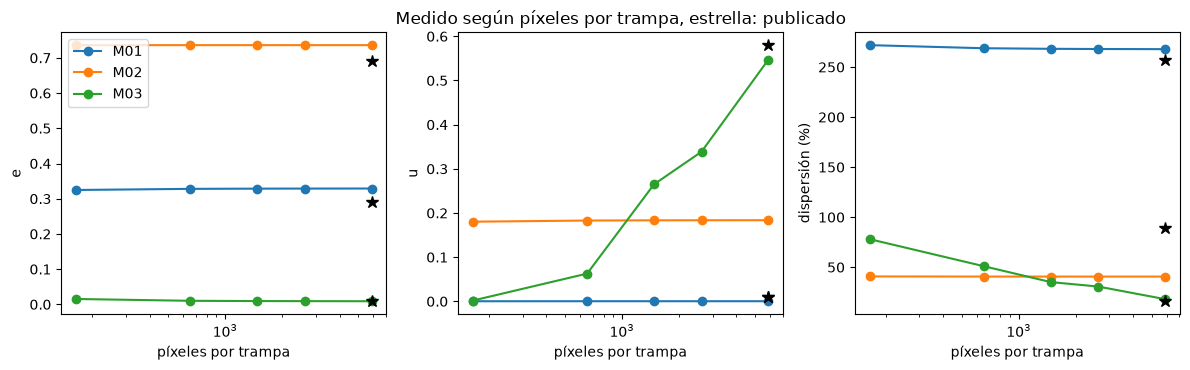

In [10]:
# los tres números frente a los píxeles por trampa; las estrellas son los valores publicados en 768 x 768
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
ppt = [n * n / len(base_traps) for n in sizes]
for k, (ax, label) in enumerate(zip(axes, ("e", "u", "dispersión (%)"))):
    for name in table:
        ax.semilogx(ppt, [table[name][n].mean(axis=0)[k] for n in sizes], "o-", label=name)
        ax.semilogx(ppt[-1], published[name][k], "k*", ms=9)
    ax.set_xlabel("píxeles por trampa")
    ax.tick_params(axis="x", which="minor", labelbottom=False)
    ax.set_ylabel(label)
axes[1].set_title("Medido según píxeles por trampa, estrella: publicado")
axes[0].legend()
fig.tight_layout()
plt.show()

La superposición y la superposición aleatoria son líneas planas: nada en $e$, $u$ o $\sigma$ depende de los píxeles por trampa, así que un SLM mayor no puede cambiarlos. La máscara aleatoria recorre todo su rango: su uniformidad sube de 0,0017 con 164 píxeles por trampa a 0,5472 con 5898, su dispersión baja de 78,05 a 18,06 por ciento y su eficiencia baja despacio de 0,0153 a 0,0089. Con 5898 píxeles por trampa la máscara aleatoria queda junto a las estrellas, lo que no hacen los otros dos métodos. La figura no muestra la variación de semilla a semilla; con tres semillas los marcadores son promedios, y la figura siguiente se lee con eso en mente.

La segunda figura muestra la razón entre lo medido y lo publicado para cada método y cada número en la grilla de 768 por 768, en un eje logarítmico donde la línea en 1 significa que el número se reproduce.

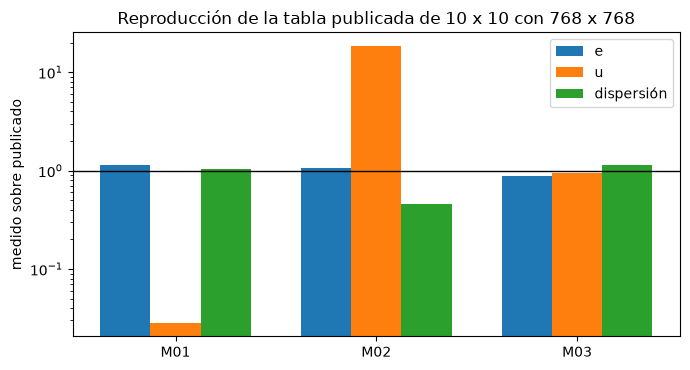

In [11]:
# medido sobre publicado, por método y por número, en la grilla más grande (1 significa reproducido)
fig, ax = plt.subplots(figsize=(7, 3.8))
width = 0.25
for k, label in enumerate(("e", "u", "dispersión")):
    ratio = [table[name][768].mean(axis=0)[k] / published[name][k] for name in published]
    ax.bar(np.arange(3) + (k - 1) * width, ratio, width, label=label)
ax.set_yscale("log")
ax.axhline(1.0, color="k", lw=1)
ax.set_xticks(range(3), list(published))
ax.set_ylabel("medido sobre publicado")
ax.set_title("Reproducción de la tabla publicada de 10 x 10 con 768 x 768")
ax.legend()
fig.tight_layout()
plt.show()

La máscara aleatoria queda a cerca de 13 por ciento de la fila publicada en los tres números, y la superposición reproduce la eficiencia y la dispersión dentro de 13 por ciento, mientras su uniformidad de 0,0003 está muy bajo el 0,01 publicado (ambos están cerca de cero: una uniformidad bajo 0,01 dice que la trampa más débil es una centésima de la más brillante). La superposición aleatoria reproduce la eficiencia con 7 por ciento de error pero no la uniformidad, que es 18 veces el valor publicado, ni la dispersión, que es 0,46 de la publicada. Leída en eje logarítmico la figura dice lo mismo que la anterior, con un hecho más: la discrepancia de la superposición aleatoria no es cuestión de unos pocos por ciento. La figura no puede decir si la tabla del artículo usó la misma convención de amplitud u otro conjunto de fases aleatorias, y este notebook no afirma una causa para la diferencia.

## Resultados

**Respuesta:** Las líneas base analíticas reproducen la comparación publicada de 10 por 10 para dos de los tres métodos: la superposición, y la máscara aleatoria cuando la grilla tiene los píxeles por trampa del artículo; la superposición aleatoria no. Con 768 por 768 píxeles, 5898 píxeles por trampa, la máscara aleatoria mide $e = 0,0089$, $u = 0,5472$ y $\sigma = 18,06$ por ciento frente a los 0,01, 0,58 y 16 publicados, y la ley $\sqrt{2}\,M/\sqrt{N}$ predice 18,4 por ciento; en la grilla de 256 por 256 de DinHot, con 655 píxeles por trampa, da $u = 0,0628$ y $\sigma = 50,97$ por ciento, que no es una falla del código sino de la cantidad de píxeles. La superposición mide $e = 0,3290$ y $\sigma = 267,88$ por ciento frente a 0,29 y 257, y su uniformidad de 0,0003 queda bajo el 0,01 publicado. La superposición aleatoria no reproduce la tabla: su $u = 0,1837$ y su $\sigma = 40,63$ por ciento son los mismos en todos los tamaños de grilla y con haz plano ($e = 0,8466$, $u = 0,1838$), y la cuantización de 8 bits cambia $u$ de 0,1986 a 0,1979, de modo que ni la grilla, ni el haz, ni la profundidad de bits explican la diferencia con los 0,01 y 89 por ciento publicados.

## Resumen

Dos de las tres líneas base analíticas coinciden con la tabla de 2007, y la tercera difiere de una manera que ninguna variable de este notebook explica: la superposición aleatoria es el punto abierto, y se informa como tal. La consecuencia práctica es para los notebooks siguientes. En el SLM de 256 por 256 de DinHot la máscara aleatoria es una mala línea base para un arreglo de 100 trampas, porque una trampa posee 655 píxeles; los métodos ponderados que siguen no dependen de esa cantidad, y se miden contra estos tres números sobre el mismo arreglo.

## Referencias

- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.